<a href="https://colab.research.google.com/github/lxie0682/cvd-women-Heartthrobs/blob/main/track-02/team/notebooks/02_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 Analysis: Track 2, Cardiovascular Health in Women

This notebook follows steps 3 to 7 of the [workflow](../../3-workflow.md): explore, build a model, check it, interpret and make a headline visual.

Run `01_cleaning.ipynb` first. Settings marked **You decide** start as `None`.

In [1]:
# Setup: run this cell first. It finds the track folder and the data.
import re, sys, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PUBLIC_REPO = "https://github.com/Harvard-Undergraduate-OpenBio/openbio-datathon-2026.git"
IN_COLAB = "google.colab" in sys.modules

def find_track_dir():
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if (folder / "track-02" / "data").is_dir():
            return folder / "track-02"
        if folder.name == "track-02" and (folder / "data").is_dir():
            return folder
    if IN_COLAB:
        dest = Path("/content/openbio-datathon-2026")
        if not dest.exists():
            subprocess.run(["git", "clone", "--depth", "1", PUBLIC_REPO, str(dest)], check=True)
        return dest / "track-02"
    return None

TRACK = find_track_dir()
TEAM = TRACK / "team" if TRACK else Path.cwd()
CLEAN = TEAM / "data_clean"
FIGURES = TEAM / "figures"
for folder in (CLEAN, FIGURES, TEAM / "docs"):
    folder.mkdir(parents=True, exist_ok=True)

SEARCH_DIRS = [d for d in [TRACK / "data" if TRACK else None, TRACK / "data" / "gbd" if TRACK else None,
               Path.cwd(), Path("/content"), Path("/content/drive/MyDrive/datathon")] if d]

def missing(name):
    print(f"Fill in {name} in the cell above, then rerun this cell.")

print("Track folder:", TRACK)
print("Team folder: ", TEAM)
if IN_COLAB:
    print("On Colab, outputs are saved in this session only. Download them or copy them into your team repository.")


Track folder: /content/openbio-datathon-2026/track-02
Team folder:  /content/openbio-datathon-2026/track-02/team
On Colab, outputs are saved in this session only. Download them or copy them into your team repository.


## Step 1: Your question

**You decide:**

- `QUESTION`: one sentence, also written in your team README.
- `DATASET`: `"d1"`, `"d2"`, `"s1"`, `"s2"` or `"s2_long"`.
- `OUTCOME`: the column you want to explain.
- `PREDICTORS`: a list of columns. Wrap ordered or text categories in `C()`, for example `"C(cholesterol_level)"`.
- `MODEL`: `"logistic"` for a yes/no outcome or `"linear"` for a number.

In [7]:
# CONFIG — define the research question and the model with BP and cholesterol
QUESTION = (
    "How much does adding blood pressure and cholesterol to age improve our "
    "ability to distinguish women with and without recorded cardiovascular "
    "disease, and does that improvement vary across age groups?"
)
DATASET = "d1"
OUTCOME = "cardio"
PREDICTORS = ["age_years", "ap_hi", "ap_lo", "C(cholesterol_level)"]
MODEL = "logistic"

READY = all(v is not None for v in (QUESTION, DATASET, OUTCOME, PREDICTORS, MODEL))
if not READY:
    print("Fill in QUESTION, DATASET, OUTCOME, PREDICTORS and MODEL, then rerun the notebook.")
    print("Example: DATASET='d1', OUTCOME='cardio', PREDICTORS=['age_years', 'C(cholesterol_level)'], MODEL='logistic'")


In [8]:
### CHECK — show where this notebook expects the cleaned CSV and whether it exists
csv_path = CLEAN / "d1_clean.csv"
print(csv_path.resolve())
print("File exists:", csv_path.is_file())

/content/openbio-datathon-2026/track-02/team/data_clean/d1_clean.csv
File exists: True


In [9]:
# Note: modified as needed to load our newly filtered data.
df = None
if READY:
    path = CLEAN / f"{DATASET}_clean.csv"
    if not path.exists():
        print(f"{path.name} not found. Run 01_cleaning.ipynb first.")
        READY = False
    else:
        # PROCESS — load the cleaned CSV and select the primary BP cohort
        df = pd.read_csv(path)

        if DATASET == "d1":
            if "bp_primary_eligible" not in df.columns:
                raise ValueError("Rerun Step 5 in Notebook 1 to export the BP eligibility flag.")

            eligible = df["bp_primary_eligible"]
            if not eligible.isin([True, False]).all():
                raise ValueError("The BP eligibility column must contain only True or False.")

            n_loaded = len(df)
            df = df.loc[eligible.eq(True)].copy()
            print(f"Primary BP cohort: {len(df):,} eligible out of {n_loaded:,} loaded.")

        for col in [c for c in df.columns if c.endswith("_level")]:
            order = {"cholesterol_level": ["normal", "above normal", "well above normal"],
                     "gluc_level": ["normal", "above normal", "well above normal"],
                     "alcohol_level": ["None", "Light", "Moderate", "Heavy"],
                     "diet_level": ["Unhealthy", "Average", "Healthy"]}.get(col)
            if order:
                df[col] = pd.Categorical(df[col], categories=order, ordered=True)
        print(QUESTION)
        print(f"Loaded {len(df):,} rows from {path.name}")


Primary BP cohort: 44,727 eligible out of 44,764 loaded.
How much does adding blood pressure and cholesterol to age improve our ability to distinguish women with and without recorded cardiovascular disease, and does that improvement vary across age groups?
Loaded 44,727 rows from d1_clean.csv


In [10]:
# CHECK — inspect age coverage and CVD counts in the proposed age groups
model_columns = ["age_years", "ap_hi", "ap_lo", "cholesterol_level", "cardio"]
print("Missing values in the planned model columns:")
print(df[model_columns].isna().sum())
print("\nRecorded outcome values (expected: 0 and 1):")
print(df["cardio"].value_counts(dropna=False))

# Use the same complete records for the baseline and expanded model comparison.
cohort = df.dropna(subset=model_columns).copy()
print(f"\nComplete records: {len(cohort):,} of {len(df):,}")
print(f"Observed age range: {cohort['age_years'].min():.1f}–"
      f"{cohort['age_years'].max():.1f} years")

# right=False puts someone aged exactly 45 in the middle band and 55 in the oldest.
age_labels = ["Under 45", "45 to under 55", "55 and older"]
cohort["age_group"] = pd.cut(
    cohort["age_years"],
    bins=[-np.inf, 45, 55, np.inf],
    labels=age_labels,
    right=False,
)

# Count both outcomes explicitly so a sparse or empty group stays visible.
counts = pd.crosstab(cohort["age_group"], cohort["cardio"])
counts = counts.reindex(index=age_labels, columns=[0, 1], fill_value=0)
counts.columns = ["Without recorded CVD", "With recorded CVD"]
counts["Total women"] = counts.sum(axis=1)
counts["Recorded CVD (%)"] = (
    100 * counts["With recorded CVD"] / counts["Total women"]
).round(1)
display(counts)

Missing values in the planned model columns:
age_years            0
ap_hi                0
ap_lo                0
cholesterol_level    0
cardio               0
dtype: int64

Recorded outcome values (expected: 0 and 1):
cardio
0    22716
1    22011
Name: count, dtype: int64

Complete records: 44,727 of 44,727
Observed age range: 29.7–64.9 years


,Without recorded CVD,With recorded CVD,Total women,Recorded CVD (%)
age_group,,,,
Under 45,4520,1743,6263,27.8
45 to under 55,10321,7952,18273,43.5
55 and older,7875,12316,20191,61.0


## Step 2: Explore

Sample size, summary statistics and each predictor plotted against the outcome. Note anything surprising.

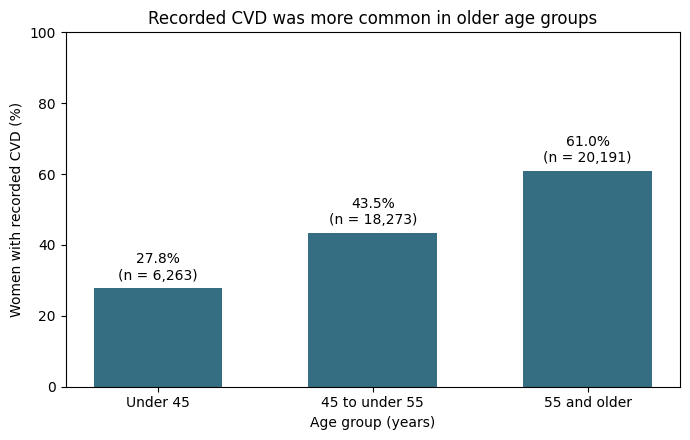

In [11]:
# PROCESS — plot the percentage with recorded CVD in each age band
def plot_cvd_by_age(counts):
    """Plot recorded CVD percentages and label each bar with its cohort size."""
    fig, ax = plt.subplots(figsize=(7, 4.5))
    bars = ax.bar(
        counts.index.astype(str),
        counts["Recorded CVD (%)"],
        color="#356E82",
        width=0.6,
    )

    # Percentages compare groups of different sizes; n shows each denominator.
    labels = [
        f"{pct:.1f}%\n(n = {total:,})"
        for pct, total in zip(counts["Recorded CVD (%)"], counts["Total women"])
    ]
    ax.bar_label(bars, labels=labels, padding=4)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Age group (years)")
    ax.set_ylabel("Women with recorded CVD (%)")
    ax.set_title("Recorded CVD was more common in older age groups")
    fig.tight_layout()
    return fig

fig = plot_cvd_by_age(counts)
fig.savefig(FIGURES / "recorded_cvd_by_age.png", dpi=200, bbox_inches="tight")
plt.show()

Rows with no missing values in these columns: 44,727 of 44,727


,cardio,age_years,ap_hi,ap_lo,cholesterol_level
count,44727.00,44727.00,44727.00,44727.00,44727
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,normal
freq,NaN,NaN,NaN,NaN,33036
mean,0.49,53.41,125.91,80.84,NaN
std,0.50,6.66,16.72,9.48,NaN
min,0.00,29.73,70.00,40.00,NaN
25%,0.00,49.38,120.00,80.00,NaN
50%,0.00,54.00,120.00,80.00,NaN
75%,1.00,58.39,140.00,90.00,NaN


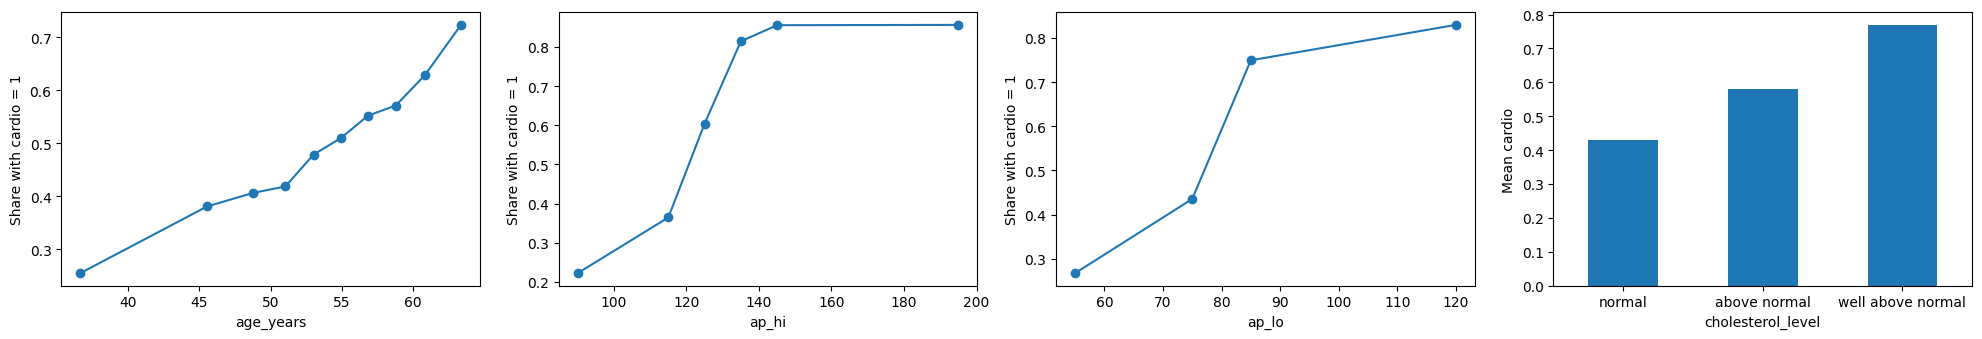

In [12]:
def base_column(term):
    m = re.match(r"C\((\w+)", term)
    return m.group(1) if m else term

def nice_term(term):
    """'C(cholesterol_level)[T.above normal]' -> 'cholesterol_level: above normal'."""
    m = re.match(r"C\((\w+)[^)]*\)\[T\.(.+)\]", term)
    return f"{m.group(1)}: {m.group(2)}" if m else term

if READY:
    cols = [OUTCOME] + [base_column(p) for p in PREDICTORS]
    data = df[cols].dropna()
    print(f"Rows with no missing values in these columns: {len(data):,} of {len(df):,}")
    display(data.describe(include="all").round(2))

    fig, axes = plt.subplots(1, len(PREDICTORS), figsize=(5 * len(PREDICTORS), 3.5), squeeze=False)
    for ax, term in zip(axes[0], PREDICTORS):
        col = base_column(term)
        if term.startswith("C(") or data[col].nunique() <= 10:
            data.groupby(col, observed=True)[OUTCOME].mean().plot.bar(ax=ax, rot=0)
            ax.set_ylabel(f"Mean {OUTCOME}")
        elif MODEL == "logistic":
            binned = pd.qcut(data[col], 10, duplicates="drop")
            share = data.groupby(binned, observed=True)[OUTCOME].mean()
            ax.plot([b.mid for b in share.index], share.values, marker="o")
            ax.set_ylabel(f"Share with {OUTCOME} = 1")
        else:
            sample = data.sample(min(len(data), 3000), random_state=0)
            ax.scatter(sample[col], sample[OUTCOME], s=5, alpha=0.3)
            ax.set_ylabel(OUTCOME)
        ax.set_xlabel(col)
    plt.tight_layout()
    plt.show()


## Step 3: Build the model

- **Logistic:** prints odds ratios (OR) with 95% confidence intervals and draws a forest plot. OR = 1 means no association.
- **Linear:** prints the slope and R². If you have one numeric predictor, it draws the fitted line with a confidence band.

Formula: cardio ~ age_years + ap_hi + ap_lo + C(cholesterol_level)


,OR,CI low,CI high,p-value
cholesterol_level: above normal,1.460,1.371,1.554,0.0
cholesterol_level: well above normal,2.693,2.504,2.895,0.0
age_years,1.057,1.053,1.060,0.0
ap_hi,1.059,1.056,1.061,0.0
ap_lo,1.012,1.009,1.016,0.0


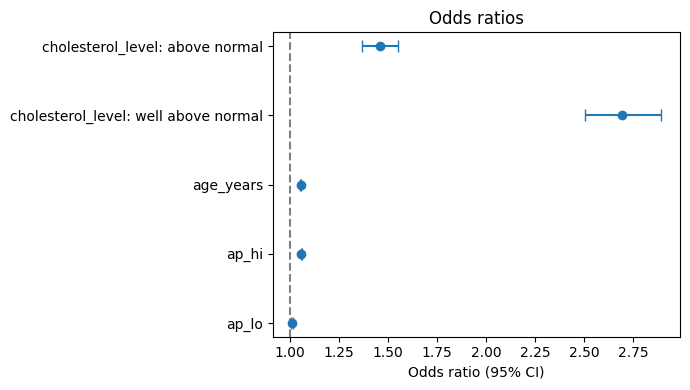

In [13]:
import statsmodels.formula.api as smf

result = None
if READY:
    formula = f"{OUTCOME} ~ " + " + ".join(PREDICTORS)
    print("Formula:", formula)
    if MODEL == "logistic":
        result = smf.logit(formula, data=data).fit(disp=False)
        table = pd.DataFrame({"OR": np.exp(result.params),
                              "CI low": np.exp(result.conf_int()[0]),
                              "CI high": np.exp(result.conf_int()[1]),
                              "p-value": result.pvalues}).drop(index="Intercept")
        table.index = [nice_term(i) for i in table.index]
        display(table.round(3))

        fig, ax = plt.subplots(figsize=(7, 0.5 * len(table) + 1.5))
        y = np.arange(len(table))[::-1]
        ax.errorbar(table["OR"], y, xerr=[table["OR"] - table["CI low"], table["CI high"] - table["OR"]],
                    fmt="o", capsize=4)
        ax.axvline(1, color="grey", linestyle="--")
        ax.set_yticks(y, table.index)
        ax.set_xlabel("Odds ratio (95% CI)")
        ax.set_title("Odds ratios")
        plt.tight_layout()
        fig.savefig(FIGURES / "forest_plot.png", dpi=200)
        plt.show()
    elif MODEL == "linear":
        result = smf.ols(formula, data=data).fit()
        table = pd.DataFrame({"Slope": result.params, "CI low": result.conf_int()[0],
                              "CI high": result.conf_int()[1], "p-value": result.pvalues})
        table.index = [nice_term(i) for i in table.index]
        display(table.round(3))
        print(f"R-squared: {result.rsquared:.3f}   n = {int(result.nobs):,}")

        if len(PREDICTORS) == 1 and not PREDICTORS[0].startswith("C("):
            x = PREDICTORS[0]
            grid = pd.DataFrame({x: np.linspace(data[x].min(), data[x].max(), 100)})
            band = result.get_prediction(grid).summary_frame(alpha=0.05)
            sample = data.sample(min(len(data), 3000), random_state=0)
            fig, ax = plt.subplots(figsize=(7, 4.5))
            ax.scatter(sample[x], sample[OUTCOME], s=6, alpha=0.3)
            ax.plot(grid[x], band["mean"], color="C1")
            ax.fill_between(grid[x], band["mean_ci_lower"], band["mean_ci_upper"], color="C1", alpha=0.3)
            ax.set_xlabel(x)
            ax.set_ylabel(OUTCOME)
            ax.set_title(f"Slope {result.params[x]:.2f}, R\u00b2 {result.rsquared:.2f}")
            plt.tight_layout()
            fig.savefig(FIGURES / "regression_line.png", dpi=200)
            plt.show()
    else:
        print('MODEL must be "logistic" or "linear".')


In [14]:
# PROCESS — fit age-only and expanded models on the same training women
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# Use cohort because it includes age_group and the complete model variables.
# Stratification keeps each age group and outcome represented in both sets.
split_groups = cohort["age_group"].astype(str) + "_" + cohort[OUTCOME].astype(str)
train, test = train_test_split(
    cohort,
    test_size=0.20,
    random_state=42,
    stratify=split_groups,
)
test = test.copy()

# PREDICTORS comes from Step 1, keeping the expanded model settings in one place.
baseline_formula = f"{OUTCOME} ~ age_years"
expanded_formula = f"{OUTCOME} ~ " + " + ".join(PREDICTORS)

baseline_fit = smf.logit(baseline_formula, data=train).fit(disp=False)
expanded_fit = smf.logit(expanded_formula, data=train).fit(disp=False)

# Store both scores on the same test rows so every comparison is paired.
test["score_age"] = baseline_fit.predict(test)
test["score_expanded"] = expanded_fit.predict(test)

print(f"Training women: {len(train):,} | Held-out women: {len(test):,}")
print("Baseline:", baseline_formula)
print("Expanded:", expanded_formula)

Training women: 35,781 | Held-out women: 8,946
Baseline: cardio ~ age_years
Expanded: cardio ~ age_years + ap_hi + ap_lo + C(cholesterol_level)


## Step 4: Check your work

- **Logistic:** fits on 80% of the rows and reports the AUC on the other 20%. 0.5 is a coin flip, 1 is perfect.
- **Linear:** plots residuals against fitted values. A clear curve or funnel shape means a straight line is a poor fit.

Then change one decision (a cleaning range or a predictor) and rerun to see whether your main result holds.

In [15]:
# CHECK — compare held-out AUCs within each age band
def compare_age_group(group):
    """Summarize discrimination for both models on the same held-out women."""
    outcome = group[OUTCOME]
    auc_age = roc_auc_score(outcome, group["score_age"])
    auc_expanded = roc_auc_score(outcome, group["score_expanded"])

    return {
        "Held-out women": len(group),
        "With recorded CVD": int(outcome.sum()),
        "Age-only AUC": auc_age,
        "Expanded AUC": auc_expanded,
        "AUC gain": auc_expanded - auc_age,
    }

rows = []
for label, group in test.groupby("age_group", observed=True, sort=True):
    rows.append({"Age group": label, **compare_age_group(group)})

auc_by_age = pd.DataFrame(rows).set_index("Age group")
display(auc_by_age.round(3))

,Held-out women,With recorded CVD,Age-only AUC,Expanded AUC,AUC gain
Age group,,,,,
Under 45,1253,349,0.585,0.835,0.251
45 to under 55,3655,1591,0.549,0.786,0.236
55 and older,4038,2463,0.575,0.728,0.153


## HERE IS THE REUSABLE PLOTTING FUNCTION!!

It creates a figure without overwriting the headline.png which will be our MAIN result figure (one of the 4 deliverable).

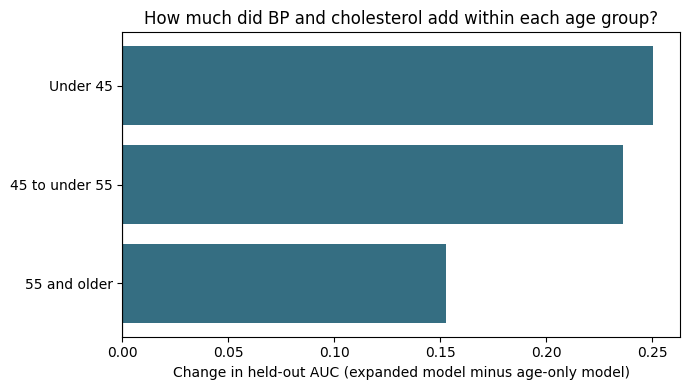

In [16]:
# PROCESS — plot the held-out gain from adding BP and cholesterol
def plot_auc_gain(summary):
    """Plot each age band's change in held-out AUC relative to age alone."""
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh(summary.index.astype(str), summary["AUC gain"], color="#356E82")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.invert_yaxis()
    ax.set_xlabel("Change in held-out AUC (expanded model minus age-only model)")
    ax.set_title("How much did BP and cholesterol add within each age group?")
    fig.tight_layout()
    return fig

fig = plot_auc_gain(auc_by_age)
fig.savefig(FIGURES / "preliminary_auc_gain_by_age.png", dpi=200, bbox_inches="tight")
plt.show()

### We used our modified cell rather than this one to avoid creating duplicate AUC (Area under ROC curve).
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, RocCurveDisplay

if READY and result is not None:
    if MODEL == "logistic":
        train, test = train_test_split(data, test_size=0.2, random_state=42, stratify=data[OUTCOME])
        holdout = smf.logit(formula, data=train).fit(disp=False)
        prob = holdout.predict(test)
        auc = roc_auc_score(test[OUTCOME], prob)
        print(f"Held-out AUC: {auc:.3f} (train n = {len(train):,}, test n = {len(test):,})")
        RocCurveDisplay.from_predictions(test[OUTCOME], prob)
        plt.plot([0, 1], [0, 1], "--", color="grey")
        plt.show()
    else:
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.scatter(result.fittedvalues, result.resid, s=5, alpha=0.3)
        ax.axhline(0, color="grey", linestyle="--")
        ax.set_xlabel("Fitted value")
        ax.set_ylabel("Residual")
        plt.tight_layout()
        plt.show()


## Step 5: Interpret

Write your main result as one plain sentence with the effect size and its confidence interval, then check it against the [ground rules](../../README.md#ground-rules). Say "associated with," not "causes."

**Your sentence:** (write it here)

## Step 6: Headline visual

One graph for a non-specialist, used in both the video and the article.

**You decide:** a title that states the finding in plain words, and everyday axis labels with units. `HEADLINE_TERMS` picks which model terms to show (logistic) and `LABELS` renames them.

In [ ]:
HEADLINE_TITLE = None    # e.g. "Higher cholesterol is linked to higher odds of heart disease in women"
X_LABEL = None
Y_LABEL = None
HEADLINE_TERMS = None    # logistic only: list of terms from the OR table, or None for all
LABELS = {}              # e.g. {"age_years": "Age (per year)"}

if READY and result is not None:
    if HEADLINE_TITLE is None:
        missing("HEADLINE_TITLE")
    fig, ax = plt.subplots(figsize=(8, 5))
    if MODEL == "logistic":
        t = table if HEADLINE_TERMS is None else table.loc[HEADLINE_TERMS]
        fig.set_size_inches(8, max(3, 1.5 + 0.7 * len(t)))
        y = np.arange(len(t))[::-1]
        ax.errorbar(t["OR"], y, xerr=[t["OR"] - t["CI low"], t["CI high"] - t["OR"]],
                    fmt="o", markersize=8, capsize=5, color="#0b7a5e")
        ax.axvline(1, color="grey", linestyle="--")
        ax.set_yticks(y, [LABELS.get(i, i) for i in t.index])
        ax.set_xlabel(X_LABEL or "Odds ratio (95% confidence interval)")
    elif len(PREDICTORS) == 1 and not PREDICTORS[0].startswith("C("):
        ax.scatter(sample[x], sample[OUTCOME], s=6, alpha=0.2, color="grey")
        ax.plot(grid[x], band["mean"], color="#0b7a5e", linewidth=2.5)
        ax.fill_between(grid[x], band["mean_ci_lower"], band["mean_ci_upper"], color="#0b7a5e", alpha=0.25)
        ax.set_xlabel(X_LABEL or x)
        ax.set_ylabel(Y_LABEL or OUTCOME)
    else:
        t = table.drop(index="Intercept")
        fig.set_size_inches(8, max(3, 1.5 + 0.7 * len(t)))
        y = np.arange(len(t))[::-1]
        ax.errorbar(t["Slope"], y, xerr=[t["Slope"] - t["CI low"], t["CI high"] - t["Slope"]],
                    fmt="o", markersize=8, capsize=5, color="#0b7a5e")
        ax.axvline(0, color="grey", linestyle="--")
        ax.set_yticks(y, [LABELS.get(i, i) for i in t.index])
        ax.set_xlabel(X_LABEL or f"Change in {OUTCOME} per unit (95% confidence interval)")
    ax.set_title(HEADLINE_TITLE or "Add a title that states your finding", fontsize=13)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.tight_layout()
    fig.savefig(FIGURES / "headline.png", dpi=300)
    plt.show()
    print("Saved", FIGURES / "headline.png")


---

This notebook is part of a student data analysis. It is not medical advice, a diagnostic tool or clinical guidance.